In [13]:
import torch
import numpy as np

In [2]:
x = torch.ones((5,4))
b = torch.from_numpy(np.array([1,2,3,4]))

In [3]:
b.shape

torch.Size([4])

In [4]:
x+b

tensor([[2., 3., 4., 5.],
        [2., 3., 4., 5.],
        [2., 3., 4., 5.],
        [2., 3., 4., 5.],
        [2., 3., 4., 5.]])

In [5]:
x = torch.randn(4,3)

In [6]:
x.reshape(2,6).shape

torch.Size([2, 6])

In [7]:
w = torch.tensor(2.0, requires_grad=True)
x = torch.tensor(3.0)

In [8]:
loss = (w*x - 10)**2

In [9]:
print(loss)

tensor(16., grad_fn=<PowBackward0>)


In [10]:
loss.backward()

In [11]:
print(loss.item())
print(w.grad.item())


16.0
-24.0


In [12]:
with torch.no_grad():
    w -= 0.1 * w.grad

In [13]:
w

tensor(4.4000, requires_grad=True)

### Practice 1

In [2]:
import copy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# Данные
torch.manual_seed(42)

X = torch.randn(1000, 10)
true_w = torch.randn(10, 1)
y = X @ true_w + 0.1 * torch.randn(1000, 1)

# Train / validation split
X_train, y_train = X[:800], y[:800]
X_val, y_val = X[800:], y[800:]

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

# Модель
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(10, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.layers(x)

In [15]:
model = SimpleNet()

In [16]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)

In [17]:
best_val_loss = float('inf')
best_state = None

In [18]:
patience = 5
min_delta = 1e-4
counter = 0

In [19]:
train_loss_history = []
val_loss_history = []
for epoch in range(30):
    model.train()
    train_total = 0.0
    for X_batch, y_batch in train_loader:
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total += loss.item() * X_batch.size(0)

    train_loss = train_total / len(train_dataset)
    train_loss_history.append(train_loss)

    model.eval()
    val_total = 0.0
    with torch.no_grad():
        for X_val, y_val in val_loader:
            predictions = model(X_val)
            loss = loss_fn(predictions, y_val)
            val_total += loss.item() * X_val.size(0)

        val_loss = val_total / len(val_dataset)

    val_loss_history.append(val_loss)

    improved = val_loss < best_val_loss - min_delta
    if improved:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        counter = 0

        torch.save({
            'epoch': epoch,
            'model_state_dict': best_state,
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': best_val_loss
        }, 'checkpoints/best_checkpoint.pt')
    else:
        counter += 1

    
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_loss': val_loss,
        'best_val_loss': best_val_loss,
        'train_loss_history': train_loss_history,
        'val_loss_history': val_loss_history,
    }, f'checkpoints/checkpoint_epoch_{epoch}.pt')

    print(f"Epoch: {epoch + 1:02d}| ",
          f"Train loss: {train_loss:.4f}",
          f"Val loss: {val_loss:.4f}")

    if counter >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

Epoch: 01|  Train loss: 6.8826 Val loss: 7.3430
Epoch: 02|  Train loss: 6.3255 Val loss: 6.6970
Epoch: 03|  Train loss: 5.7291 Val loss: 6.0008
Epoch: 04|  Train loss: 5.0795 Val loss: 5.2404
Epoch: 05|  Train loss: 4.3775 Val loss: 4.4606
Epoch: 06|  Train loss: 3.6756 Val loss: 3.6631
Epoch: 07|  Train loss: 2.9735 Val loss: 2.9574
Epoch: 08|  Train loss: 2.3553 Val loss: 2.3123
Epoch: 09|  Train loss: 1.8151 Val loss: 1.7724
Epoch: 10|  Train loss: 1.3731 Val loss: 1.3405
Epoch: 11|  Train loss: 1.0224 Val loss: 1.0060
Epoch: 12|  Train loss: 0.7554 Val loss: 0.7551
Epoch: 13|  Train loss: 0.5583 Val loss: 0.5718
Epoch: 14|  Train loss: 0.4210 Val loss: 0.4372
Epoch: 15|  Train loss: 0.3237 Val loss: 0.3454
Epoch: 16|  Train loss: 0.2579 Val loss: 0.2852
Epoch: 17|  Train loss: 0.2150 Val loss: 0.2406
Epoch: 18|  Train loss: 0.1848 Val loss: 0.2108
Epoch: 19|  Train loss: 0.1642 Val loss: 0.1891
Epoch: 20|  Train loss: 0.1492 Val loss: 0.1712
Epoch: 21|  Train loss: 0.1372 Val loss:

In [20]:
model.load_state_dict(best_state)

<All keys matched successfully>

In [11]:
import matplotlib.pyplot as plt

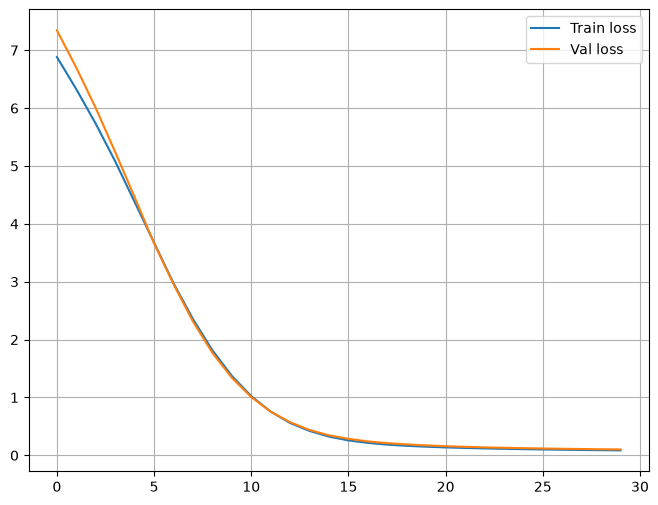

In [21]:
plt.figure(figsize=(8,6))
plt.plot(np.arange(30), train_loss_history, label='Train loss')
plt.plot(np.arange(30), val_loss_history, label='Val loss')
plt.legend()
plt.grid(True)
plt.show()

In [22]:
checkpoint = torch.load(
    "checkpoints/checkpoint_epoch_29.pt",
    map_location="cpu",
    weights_only=True
)

print(checkpoint.keys())
print("Epoch:", checkpoint["epoch"])
print("Best val loss:", checkpoint["best_val_loss"])
print("Optimizer state:", checkpoint["optimizer_state_dict"].keys())

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss', 'best_val_loss', 'train_loss_history', 'val_loss_history'])
Epoch: 29
Best val loss: 0.10225761592388154
Optimizer state: dict_keys(['state', 'param_groups'])


In [28]:
model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

In [30]:
train_loss_history = checkpoint["train_loss_history"]
val_loss_history = checkpoint["val_loss_history"]

In [31]:
start_epoch = checkpoint["epoch"] + 1

In [32]:
for epoch in range(start_epoch, 100):
    model.train()
    train_total = 0.0
    for X_batch, y_batch in train_loader:
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total += loss.item() * X_batch.size(0)

    train_loss = train_total / len(train_dataset)
    train_loss_history.append(train_loss)

    model.eval()
    val_total = 0.0
    with torch.no_grad():
        for X_val, y_val in val_loader:
            predictions = model(X_val)
            loss = loss_fn(predictions, y_val)
            val_total += loss.item() * X_val.size(0)

        val_loss = val_total / len(val_dataset)

    val_loss_history.append(val_loss)

    improved = val_loss < best_val_loss - min_delta
    if improved:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        counter = 0

        torch.save({
            'epoch': epoch,
            'model_state_dict': best_state,
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': best_val_loss
        }, 'checkpoints/best_checkpoint.pt')
    else:
        counter += 1

    
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_loss': val_loss,
        'best_val_loss': best_val_loss,
        'train_loss_history': train_loss_history,
        'val_loss_history': val_loss_history,
    }, f'checkpoints/checkpoint_epoch_{epoch}.pt')

    print(f"Epoch: {epoch + 1:02d}| ",
          f"Train loss: {train_loss:.4f}",
          f"Val loss: {val_loss:.4f}")

    if counter >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

Epoch: 31|  Train loss: 0.0829 Val loss: 0.0979
Epoch: 32|  Train loss: 0.0794 Val loss: 0.0947
Epoch: 33|  Train loss: 0.0762 Val loss: 0.0916
Epoch: 34|  Train loss: 0.0733 Val loss: 0.0885
Epoch: 35|  Train loss: 0.0709 Val loss: 0.0869
Early stopping at epoch 35


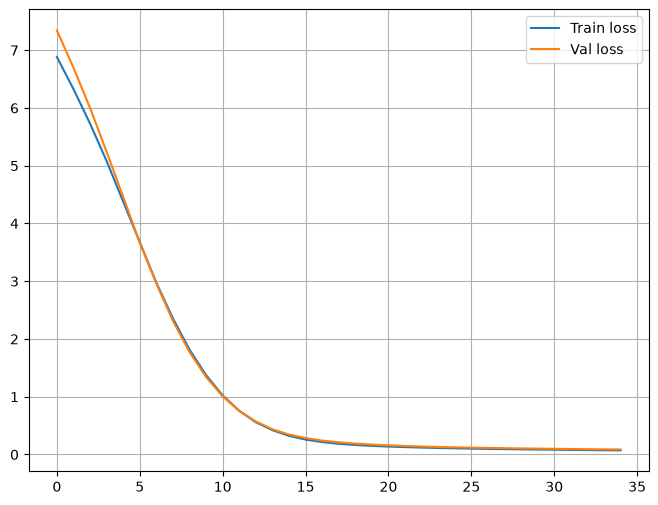

In [33]:
plt.figure(figsize=(8,6))
plt.plot(np.arange(len(train_loss_history)), train_loss_history, label='Train loss')
plt.plot(np.arange(len(val_loss_history)), val_loss_history, label='Val loss')
plt.legend()
plt.grid(True)
plt.show()